# 04. EDA Avancee

Analyse plus fine des signaux de fraude apres nettoyage : croisements cibles, dynamique temporelle, variables has_X et correlations.


In [1]:
# Importation des bibliothèques principales
from pyspark.sql import SparkSession
from pyspark.sql.functions import *
from pyspark.sql.types import *
from pyspark.sql.functions import col, round as spark_round

from pyspark.ml.stat import *
from pyspark.ml import Pipeline
from pyspark.ml.functions import vector_to_array
from pyspark.ml.feature import  VectorAssembler , RobustScaler
from pyspark.ml.feature import StringIndexer, OneHotEncoder, StandardScaler
from pyspark.ml.classification import RandomForestClassifier,LogisticRegression,GBTClassifier
from pyspark.ml.evaluation import BinaryClassificationEvaluator ,MulticlassClassificationEvaluator
from pyspark.mllib.evaluation import MulticlassMetrics
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

#  Visualisation et analyse complémentaire

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from builtins import round


In [2]:
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name.lower() == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
NOTEBOOK_DIR = PROJECT_DIR / "notebooks"
ARTIFACTS_ROOT = PROJECT_DIR / "artifacts"
MODELS_ROOT = PROJECT_DIR / "models"
INPUT_STAGE_DIR = ARTIFACTS_ROOT / "03_quality_cleaning" / "data"

for _dir in (ARTIFACTS_ROOT, MODELS_ROOT, INPUT_STAGE_DIR):
    _dir.mkdir(parents=True, exist_ok=True)

In [3]:
# Création de la session Spark

spark = SparkSession.builder \
    .appName("DetectionFraude") \
    .master("local[8]") \
    .config("spark.driver.memory", "10g") \
    .config("spark.sql.execution.arrow.pyspark.enabled", "true") \
    .config("spark.sql.shuffle.partitions", "8") \
    .getOrCreate() 

# Affichage de la session pour vérification

spark 

In [4]:
# fonciton nettoyage de mémoire 
def cleanup(*vars_to_del):
    for var in vars_to_del:
        del var
    import gc; gc.collect()
    spark.catalog.clearCache()

In [5]:
df = spark.read.parquet((INPUT_STAGE_DIR / "02_train_clean.parquet").as_posix())

# 5. Analyse exploratoire approfondie (EDA avancée).

####  Objectif de cette section : Explorer les structures fines du dataset et les patterns de fraude

Cette étape vise à **approfondir l’analyse statistique** après le nettoyage, afin de :

1. Identifier les **relations entre les variables et la cible `isFraud`**
2. Détecter des **corrélations ou effets de seuils**
3. Repérer les **groupes à risque élevé de fraude**
4. Préparer le terrain pour un **feature engineering guidé par les données**

L’analyse sera structurée selon 4 axes principaux :

1. **Analyse croisée `isFraud` vs variables clés**  
   - Numériques : `TransactionAmt`, `D1`, `C1`, etc.  
   - Catégorielles : `ProductCD`, `card4`, `card6`, `P_emaildomain`, etc.

2. **Analyse temporelle**  
   - Étude de l’évolution des fraudes dans le temps (`TransactionDT`, `D*`)

3. **Analyse par groupe spécifique**  
   - Variables indicatrices (`has_identity`, `has_X`, etc.)
   - Segments à risque (montants élevés, absence d'identité, etc.)

4. **Analyse des corrélations numériques**  
   - Détection de redondances  
   - Préparation à la sélection de variables ou réduction de dimension

### 5.1 Analyse croisée : `TransactionAmt` vs `isFraud`

####  Objectif : Étudier la répartition du montant des transactions (`TransactionAmt`) en fonction de la présence ou non de fraude

Le montant d’une transaction est une **variable clé** dans les systèmes de détection de fraude.


In [6]:
# Statistiques par classe (fraude vs non fraude)
df.groupBy("isFraud").agg(
    count("*").alias("n_obs"),
    spark_round(mean("TransactionAmt"), 2).alias("mean_amt"),
    spark_round(expr("percentile_approx(TransactionAmt, 0.5)"), 2).alias("median_amt"),
    spark_round(expr("percentile_approx(TransactionAmt, 0.9)"), 2).alias("p90_amt"),
    spark_round(max("TransactionAmt"), 2).alias("max_amt")
).orderBy("isFraud").show()

+-------+------+--------+----------+-------+--------+
|isFraud| n_obs|mean_amt|median_amt|p90_amt| max_amt|
+-------+------+--------+----------+-------+--------+
|      0|569877|  134.51|      68.5|  266.0|31937.39|
|      1| 20663|  149.24|      75.0|  335.0|  5191.0|
+-------+------+--------+----------+-------+--------+



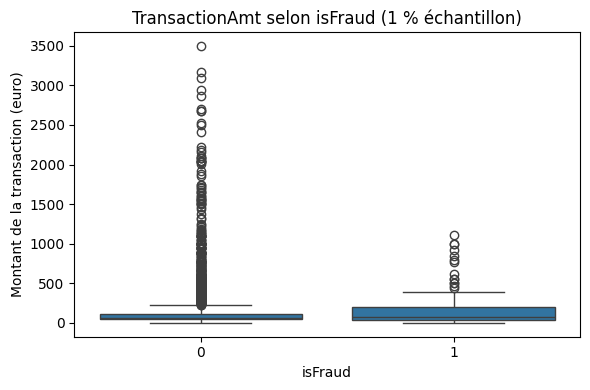

In [7]:
# échantillon pour visualisation
df_pd = df.select("TransactionAmt", "isFraud").sample(fraction=0.01).toPandas()

plt.figure(figsize=(6, 4))
sns.boxplot(x="isFraud", y="TransactionAmt", data=df_pd)
plt.title("TransactionAmt selon isFraud (1 % échantillon)")
plt.xlabel("isFraud")
plt.ylabel("Montant de la transaction (euro)")
plt.tight_layout()
plt.show()


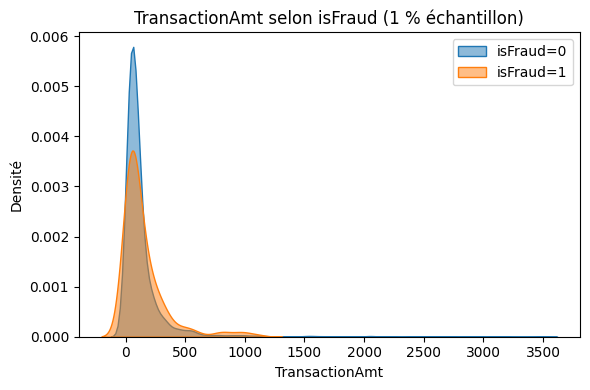

In [8]:
plt.figure(figsize=(6, 4))
for label in [0, 1]:
    subset = df_pd[df_pd["isFraud"] == label]
    sns.kdeplot(subset["TransactionAmt"], label=f"isFraud={label}", fill=True, alpha=0.5)
plt.legend()
plt.title("TransactionAmt selon isFraud (1 % échantillon)")
plt.xlabel("TransactionAmt")
plt.ylabel("Densité")
plt.tight_layout()
plt.show()

cleanup(df_pd)


In [9]:
from scipy.stats import mannwhitneyu

df_pd_full = df.select("TransactionAmt", "isFraud").toPandas()

fraud = df_pd_full[df_pd_full["isFraud"] == 1]["TransactionAmt"]
nonfraud = df_pd_full[df_pd_full["isFraud"] == 0]["TransactionAmt"]

# Test de Mann-Whitney 
stat, p_value = mannwhitneyu(fraud, nonfraud, alternative="two-sided")

print(f"Statistic: {stat}")
print(f"P-value: {p_value}")

Statistic: 5858540820.5
P-value: 0.22590783497976064


### Interprétation – `TransactionAmt` et `isFraud`

Les transactions frauduleuses présentent des statistiques descriptives légèrement plus élevées :

- montant moyen : **149,24** en fraude contre **134,51** en non-fraude ;
- médiane : **75** contre **68,50** ;
- 90e percentile : **335** contre **266**.

Les valeurs maximales sont toutefois plus élevées parmi les transactions non frauduleuses :

- **31 937,39** en non-fraude ;
- **5 191** en fraude.

Le test de Mann–Whitney ne met pas en évidence de différence statistiquement significative entre les distributions globales :
**p = 0,226 > 0,05**
donc :
- `TransactionAmt` est une variable **informative** à conserver.
- Elle sera possiblement **transformée (log1p)** et **binarisée (`is_high_amount`)** dans le Feature Engineering.

### Analyse croisée : `D1` vs `isFraud` 

####  Objectif : Étudier l'effet du délai comportemental `D1` selon la classe de fraude

`D1` correspond à un **delta temporel** lié à l’activité de l’utilisateur (souvent le nombre de jours depuis la dernière interaction connue).  
Des valeurs extrêmes ou très faibles peuvent signaler un comportement inhabituel.

In [10]:
df.groupBy("isFraud").agg(
    count("*").alias("n_obs"),
    spark_round(mean("D1"), 2).alias("mean_D1"),
    spark_round(expr("percentile_approx(D1, 0.5)"), 2).alias("median_D1"),
    spark_round(expr("percentile_approx(D1, 0.9)"), 2).alias("p90_D1"),
    spark_round(max("D1"), 2).alias("max_D1")
).orderBy("isFraud").show()

+-------+------+-------+---------+------+------+
|isFraud| n_obs|mean_D1|median_D1|p90_D1|max_D1|
+-------+------+-------+---------+------+------+
|      0|569877|  96.16|      3.0| 366.0| 640.0|
|      1| 20663|  38.63|      0.0| 128.0| 637.0|
+-------+------+-------+---------+------+------+



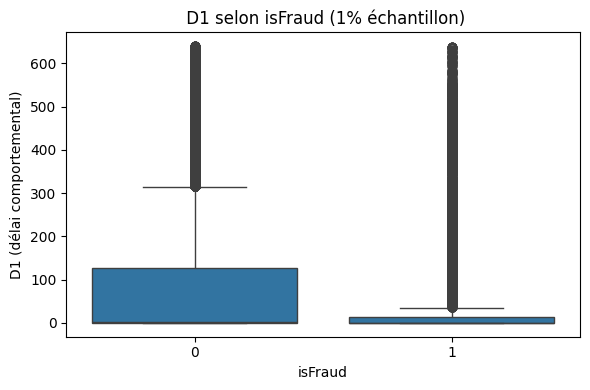

In [11]:
df_pd0 = df.select("D1", "isFraud").where(col("D1").isNotNull()).toPandas()

plt.figure(figsize=(6, 4))
sns.boxplot(x="isFraud", y="D1", data=df_pd0)
plt.title(" D1 selon isFraud (1% échantillon)")
plt.xlabel("isFraud")
plt.ylabel("D1 (délai comportemental)")
plt.tight_layout()
plt.show()


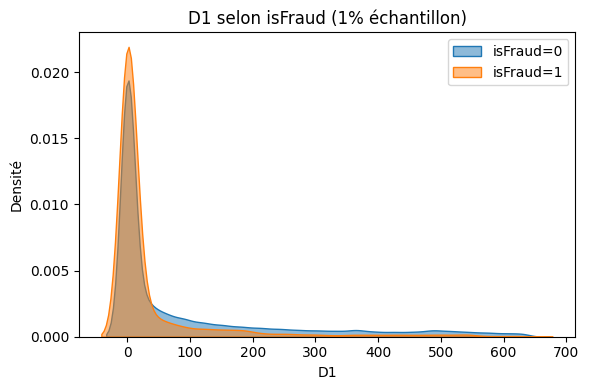

In [12]:
plt.figure(figsize=(6, 4))
for label in [0, 1]:
    subset = df_pd0[df_pd0["isFraud"] == label]
    sns.kdeplot(subset["D1"], label=f"isFraud={label}", fill=True, alpha=0.5)
plt.legend()
plt.title("D1 selon isFraud (1% échantillon)")
plt.xlabel("D1")
plt.ylabel("Densité")
plt.tight_layout()
plt.show()

cleanup(df_pd0)


### Interprétation – `D1` et `isFraud`

La distribution de `D1` diffère sensiblement entre les deux classes :

- moyenne : **38,63** en fraude contre **96,16** en non-fraude ;
- médiane : **0** contre **3** ;
- 90e percentile : **128** contre **366**.

Les transactions frauduleuses sont donc associées à des valeurs généralement plus faibles de `D1`.

Comme la signification métier précise des variables `D*` est anonymisée, cette différence ne peut pas être directement interprétée comme la présence de comptes récents. `D1` constitue néanmoins une variable candidate intéressante, dont l’utilité devra être confirmée par le modèle.

Un indicateur `is_recent_activity`, défini à partir de `D1 == 0`, pourra être évalué lors du feature engineering.


### Analyse croisée : `C1` vs `isFraud`

####  Objectif : Étudier la distribution de la variable `C1` en fonction de la fraude

`C1` fait partie des variables comportementales agrégées (souvent liées à l’usage de la carte ou du compte).  
Des valeurs extrêmes peuvent refléter un **usage intensif, automatisé ou anormal**.

In [13]:
df.groupBy("isFraud").agg(
    count("*").alias("n_obs"),
    spark_round(mean("C1"), 2).alias("mean_C1"),
    spark_round(expr("percentile_approx(C1, 0.5)"), 2).alias("median_C1"),
    spark_round(expr("percentile_approx(C1, 0.9)"), 2).alias("p90_C1"),
    spark_round(max("C1"), 2).alias("max_C1")
).orderBy("isFraud").show()

+-------+------+-------+---------+------+------+
|isFraud| n_obs|mean_C1|median_C1|p90_C1|max_C1|
+-------+------+-------+---------+------+------+
|      0|569877|  13.31|      1.0|   6.0|4685.0|
|      1| 20663|  35.54|      2.0|  30.0|4682.0|
+-------+------+-------+---------+------+------+



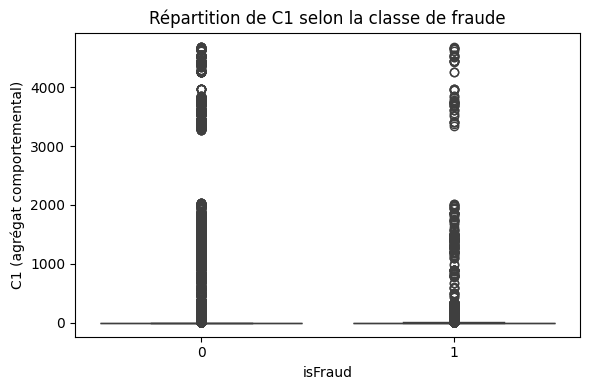

In [14]:
df_pd1 = df.select("C1", "isFraud").where(col("C1").isNotNull()).toPandas()

plt.figure(figsize=(6, 4))
sns.boxplot(x="isFraud", y="C1", data=df_pd1)
plt.title("Répartition de C1 selon la classe de fraude")
plt.xlabel("isFraud")
plt.ylabel("C1 (agrégat comportemental)")
plt.tight_layout()
plt.show()


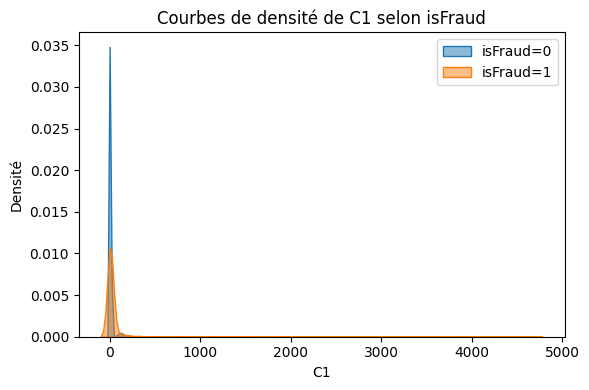

In [15]:
plt.figure(figsize=(6, 4))
for label in [0, 1]:
    subset = df_pd1[df_pd1["isFraud"] == label]
    sns.kdeplot(subset["C1"], label=f"isFraud={label}", fill=True, alpha=0.5)
plt.legend()
plt.title("Courbes de densité de C1 selon isFraud")
plt.xlabel("C1")
plt.ylabel("Densité")
plt.tight_layout()
plt.show()

cleanup(df_pd1)


###  Interprétation – `C1` vs `isFraud`

- Les transactions frauduleuses présentent des **valeurs moyennes de `C1` beaucoup plus élevées** (35,5 contre 13,3).
- La **médiane est aussi doublée en fraude** (2 contre 1), avec un 90e percentile à 30 contre 6.
- Cela suggère que **les fraudeurs sont associés à une intensité comportementale beaucoup plus forte** sur ce compteur.
- Le boxplot montre une **distribution plus étalée en fraude**, avec également des outliers dans les deux classes.

 Conclusion :
- `C1` est une variable **très informative** pour capturer des comportements atypiques.
- À conserver pour la modélisation, avec éventuelle **normalisation** ou **binning** selon sa distribution.


### Analyse croisée du ratio : `C1/D1` vs `isFraud`

####  Objectif : Explorer  le **rapport comportementale  entre (`C1`) et (`D1`)** permet de mieux distinguer les fraudes.

Ce ratio `C1 / D1` capture une idée d’**intensité récente** : un comportement très fréquent dans un court laps de temps peut être suspect.

####  Construction du ratio `C1_sur_D1`

In [16]:
# Création de la feature ratio qu'on recréera dans feature construction .
df_test = df.withColumn("C1_sur_D1", when(col("D1") == 0, col("C1")).otherwise(col("C1") / (col("D1") + 1e-6)))
df_test.groupBy("isFraud").agg(
    count("*").alias("n_obs"),
    spark_round(mean("C1_sur_D1"), 2).alias("mean_ratio"),
    spark_round(expr("percentile_approx(C1_sur_D1, 0.5)"), 2).alias("median_ratio"),
    spark_round(expr("percentile_approx(C1_sur_D1, 0.9)"), 2).alias("p90_ratio"),
    spark_round(max("C1_sur_D1"), 2).alias("max_ratio")
).orderBy("isFraud").show()

+-------+------+----------+------------+---------+---------+
|isFraud| n_obs|mean_ratio|median_ratio|p90_ratio|max_ratio|
+-------+------+----------+------------+---------+---------+
|      0|569877|      6.59|         1.0|      2.0|   4685.0|
|      1| 20663|     25.86|         1.0|     16.0|   4682.0|
+-------+------+----------+------------+---------+---------+



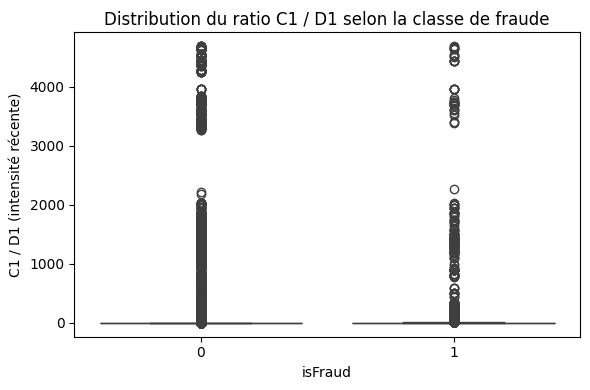

In [17]:
df_sample = df_test.select("C1_sur_D1", "isFraud").where(col("C1_sur_D1").isNotNull()).toPandas()

plt.figure(figsize=(6, 4))
sns.boxplot(x="isFraud", y="C1_sur_D1", data=df_sample)
plt.title("Distribution du ratio C1 / D1 selon la classe de fraude")
plt.xlabel("isFraud")
plt.ylabel("C1 / D1 (intensité récente)")
plt.tight_layout()
plt.show()


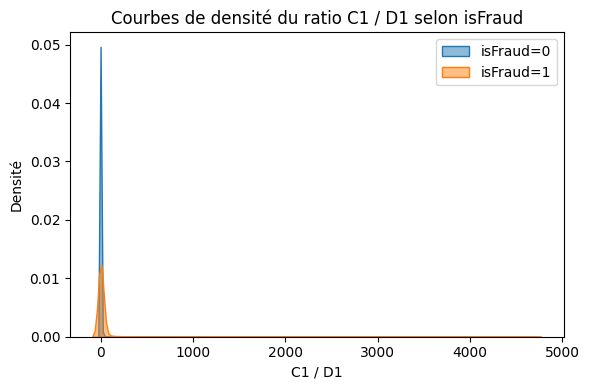

In [18]:
plt.figure(figsize=(6, 4))
for label in [0, 1]:
    subset = df_sample[df_sample["isFraud"] == label]
    sns.kdeplot(subset["C1_sur_D1"], label=f"isFraud={label}", fill=True, alpha=0.5)
plt.legend()
plt.title("Courbes de densité du ratio C1 / D1 selon isFraud")
plt.xlabel("C1 / D1")
plt.ylabel("Densité")
plt.tight_layout()
plt.show()

cleanup(df_sample)


In [19]:
from scipy.stats import mannwhitneyu

df_pd_full = df_test.select("C1_sur_D1", "isFraud").toPandas()

fraud = df_pd_full[df_pd_full["isFraud"] == 1]["C1_sur_D1"]
nonfraud = df_pd_full[df_pd_full["isFraud"] == 0]["C1_sur_D1"]

# Test de Mann-Whitney 
stat, p_value = mannwhitneyu(fraud, nonfraud, alternative="two-sided")

print(f"Statistic: {stat}")
print(f"P-value: {p_value}")

Statistic: 7844512023.5
P-value: 0.0


####  Interprétation – `C1 / D1` vs `isFraud`

- Les deux classes ont une **médiane identique (1.0)**, ce qui suggère qu’une grande partie des transactions ont un ratio modéré.
- En revanche :
  - La **moyenne est presque 4 fois plus élevée en cas de fraude** (25.86 vs 6.59)
  - Le **90e percentile explose en cas de fraude** (16 vs 2)
- Cela indique qu’**une fraction non négligeable des fraudes est associée à une activité très intense sur un laps de temps court** (haut `C1`, bas `D1`)
- Le boxplot confirme la **présence d’outliers élevés chez les fraudes**, et une **dispersion plus marquée**.

 **Conclusion :** le ratio `C1 / D1` semble **informativement puissant**, mais **fortement asymétrique**.
- Il pourrait être **log-transformé (`log1p`)**
- Ou binarisé (`is_high_intensity`) dans le Feature Engineering

### Analyse croisée : `ProductCD` vs `isFraud` [Catégorielle]

####  Objectif : Étudier si certains types de produits (`ProductCD`) sont plus exposés à la fraude

La variable `ProductCD` indique le **type de produit acheté** (catégorie de transaction).  
Certaines catégories peuvent être **ciblées préférentiellement par les fraudeurs** (ex : produits numériques, abonnements).


In [20]:
fraude_par_produit = (
    df.groupBy("ProductCD", "isFraud")
      .count()
      .groupBy("ProductCD")
      .pivot("isFraud", [0, 1])
      .sum("count")
      .fillna(0))

fraude_par_produit = fraude_par_produit.withColumn(
    "taux_fraude_%", spark_round(col("1") / (col("0") + col("1")) * 100, 2)
).orderBy("taux_fraude_%", ascending=False)

fraude_par_produit.show()

+---------+------+----+-------------+
|ProductCD|     0|   1|taux_fraude_%|
+---------+------+----+-------------+
|        C| 60511|8008|        11.69|
|        S| 10942| 686|          5.9|
|        H| 31450|1574|         4.77|
|        R| 36273|1426|         3.78|
|        W|430701|8969|         2.04|
+---------+------+----+-------------+



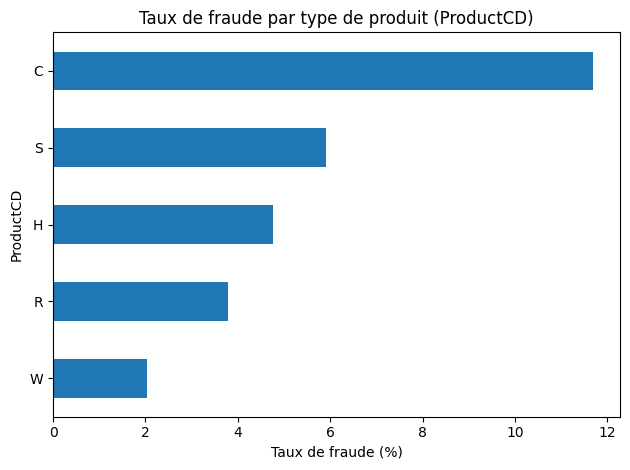

In [21]:
fraude_pd = df.groupBy("ProductCD", "isFraud").count().toPandas()
pivot = fraude_pd.pivot(index="ProductCD", columns="isFraud", values="count").fillna(0)
pivot["taux_fraude_%"] = (pivot[1] / (pivot[0] + pivot[1]) * 100).round(2)


pivot[["taux_fraude_%"]].sort_values(by="taux_fraude_%").plot(kind="barh", legend=False)
plt.title("Taux de fraude par type de produit (ProductCD)")
plt.xlabel("Taux de fraude (%)")
plt.ylabel("ProductCD")
plt.tight_layout()
plt.show()

cleanup(fraude_pd, pivot)

In [22]:
from scipy.stats import chi2_contingency

# table de contingence
contingency = pd.crosstab(df.select("ProductCD", "isFraud").toPandas()["ProductCD"],
                          df.select("ProductCD", "isFraud").toPandas()["isFraud"])

# Test du chi2
chi2, p_value, dof, expected = chi2_contingency(contingency)

print(f"Statistic: {chi2:.2f}")
print(f"P-value: {p_value:.4e}")

Statistic: 16742.17
P-value: 0.0000e+00


### Interprétation – `ProductCD` et `isFraud`

Les taux de fraude diffèrent selon `ProductCD` :

- `C` : **11,69 %** ;
- `S` : **5,90 %** ;
- `H` : **4,77 %** ;
- `R` : **3,78 %** ;
- `W` : **2,04 %**.

La modalité `W` est la plus fréquente avec **439 670 transactions**, tandis que `C` présente le taux de fraude le plus élevé.

Le test du chi² confirme l’existence d’une association statistique entre `ProductCD` et `isFraud`. Le V de Cramér, proche de **0,168**, indique toutefois une association d’intensité modérée.

`ProductCD` sera conservée et le flag `is_product_C` pourra être évalué lors du feature engineering.

### Analyse croisée : `card4` vs `isFraud` [Catégorielle]

####  Objectif : Étudier l’influence du type de carte (`card4`) sur le risque de fraude

`card4` désigne le **réseau de la carte bancaire** utilisée (Visa, Mastercard, etc.).  
Certaines marques peuvent être **plus exposées** en raison de leur popularité ou de failles spécifiques.

In [23]:
fraude_par_card4 = (
    df.groupBy("card4", "isFraud")
      .count()
      .groupBy("card4")
      .pivot("isFraud", [0, 1])
      .sum("count")
      .fillna(0)
)

fraude_par_card4 = fraude_par_card4.withColumn(
    "taux_fraude_%", spark_round(col("1") / (col("0") + col("1")) * 100, 2)
).orderBy("taux_fraude_%", ascending=False)

fraude_par_card4.show()

+----------------+------+-----+-------------+
|           card4|     0|    1|taux_fraude_%|
+----------------+------+-----+-------------+
|        discover|  6137|  514|         7.73|
|            visa|371394|13373|         3.48|
|      mastercard|182721| 6496|         3.43|
|american express|  8089|  239|         2.87|
|         unknown|  1536|   41|          2.6|
+----------------+------+-----+-------------+



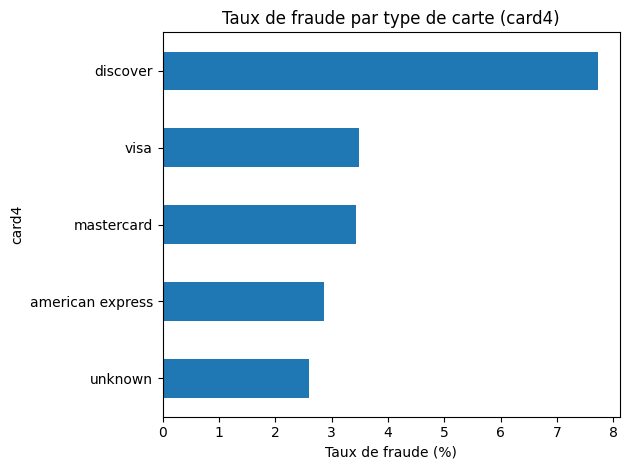

In [24]:
fraude_pd = df.groupBy("card4", "isFraud").count().toPandas()
pivot = fraude_pd.pivot(index="card4", columns="isFraud", values="count").fillna(0)
pivot["taux_fraude_%"] = (pivot[1] / (pivot[0] + pivot[1]) * 100).round(2)


pivot[["taux_fraude_%"]].sort_values(by="taux_fraude_%").plot(kind="barh", legend=False)
plt.title("Taux de fraude par type de carte (card4)")
plt.xlabel("Taux de fraude (%)")
plt.ylabel("card4")
plt.tight_layout()
plt.show()

cleanup(fraude_pd, pivot)

In [25]:
from scipy.stats import chi2_contingency

contingency = pivot[[0,1]]  

# Test du chi2
chi2_stat, p_val, dof, expected = chi2_contingency(contingency)

print(f"Chi² statistic: {chi2_stat:.2f}")
print(f"P-value: {p_val:.4e}")


Chi² statistic: 368.90
P-value: 1.4528e-78


###  Interprétation – `card4` vs `isFraud`

- La carte **Discover** présente le **taux de fraude le plus élevé (7,73 %)**, bien au-dessus des autres réseaux.
- Les cartes **Visa** et **Mastercard**, très répandues, affichent un taux proche de **3,4 %**, dans la moyenne globale.
- Les cartes **American Express** et les cas **inconnus** sont moins exposés (= 2,6–2,9 %).

 Conclusion :
- `card4` est une variable catégorielle **modérément informative**, à **conserver pour la modélisation**.
- Il peut être pertinent de regrouper les modalités rares ou créer un flag `is_discover_card` dans le Feature Engineering.


### Analyse croisée : `card6` vs `isFraud` [catégorielle]

####  Objectif : Évaluer si le type de carte (`card6`) influence le risque de fraude

`card6` indique la **nature de la carte bancaire** : débit, crédit, prépayée, etc.  
Certains types peuvent être **plus vulnérables** selon leur usage ou leur vérification d’identité.

In [26]:
fraude_par_card6 = (
    df.groupBy("card6", "isFraud")
      .count()
      .groupBy("card6")
      .pivot("isFraud", [0, 1])
      .sum("count")
      .fillna(0)
)

fraude_par_card6 = fraude_par_card6.withColumn(
    "taux_fraude_%", spark_round(col("1") / (col("0") + col("1")) * 100, 2)
).orderBy("taux_fraude_%", ascending=False)

fraude_par_card6.show()

+---------------+------+-----+-------------+
|          card6|     0|    1|taux_fraude_%|
+---------------+------+-----+-------------+
|         credit|139036| 9950|         6.68|
|        unknown|  1532|   39|         2.48|
|          debit|429264|10674|         2.43|
|    charge card|    15|    0|          0.0|
|debit or credit|    30|    0|          0.0|
+---------------+------+-----+-------------+



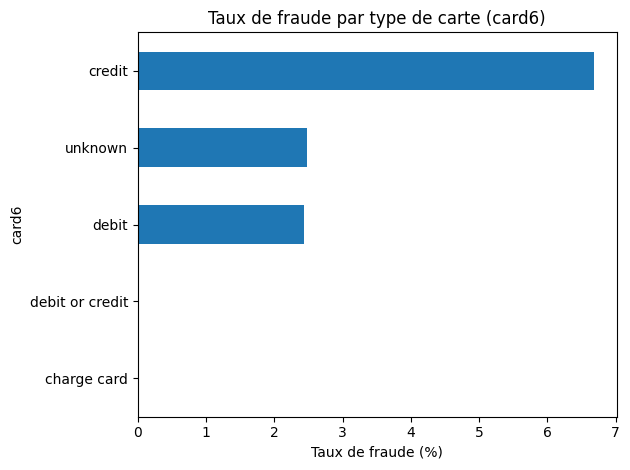

In [27]:
fraude_pd = df.groupBy("card6", "isFraud").count().toPandas()
pivot = fraude_pd.pivot(index="card6", columns="isFraud", values="count").fillna(0)
pivot["taux_fraude_%"] = (pivot[1] / (pivot[0] + pivot[1]) * 100).round(2)

pivot[["taux_fraude_%"]].sort_values(by="taux_fraude_%").plot(kind="barh", legend=False)
plt.title("Taux de fraude par type de carte (card6)")
plt.xlabel("Taux de fraude (%)")
plt.ylabel("card6")
plt.tight_layout()
plt.show()
cleanup(fraude_pd, pivot)

###  Interprétation – `card6` vs `isFraud`

- Les cartes de **crédit** présentent un **taux de fraude élevé (6,68 %)**, bien supérieur aux cartes de débit (2,43 %).
- Les types rares (`charge card`, `debit or credit`) affichent **zéro fraude**, mais avec un **nombre d’occurrences trop faible** pour conclure.
- Les cartes **"unknown"** restent modérément exposées (2,48 %).

 Conclusion :
- Le type de carte (`card6`) est **clairement discriminant**, surtout entre **crédit** et **débit**.
- À conserver pour la modélisation, avec une possible transformation binaire : `is_credit_card`.


### Analyse croisée : `card4` vs `card6` [catégorielle]

####  Objectif : Comprendre les combinaisons les plus fréquentes entre **réseau de carte** (`card4`) et **type de carte** (`card6`)

Ce croisement permet d’identifier les **paires les plus courantes** dans les transactions.  
Certaines combinaisons peuvent être **plus représentatives du comportement normal**, ou à l’inverse, **plus exposées à la fraude**.

In [28]:
df.select("card6", "card4").groupBy("card6", "card4").count().orderBy("count", ascending=False).show()

+---------------+----------------+------+
|          card6|           card4| count|
+---------------+----------------+------+
|          debit|            visa|301023|
|          debit|      mastercard|138415|
|         credit|            visa| 83732|
|         credit|      mastercard| 50772|
|         credit|american express|  8175|
|         credit|        discover|  6304|
|        unknown|         unknown|  1565|
|          debit|        discover|   347|
|          debit|american express|   144|
|debit or credit|      mastercard|    30|
|    charge card|            visa|    12|
|          debit|         unknown|     9|
|        unknown|american express|     6|
|         credit|         unknown|     3|
|    charge card|american express|     3|
+---------------+----------------+------+



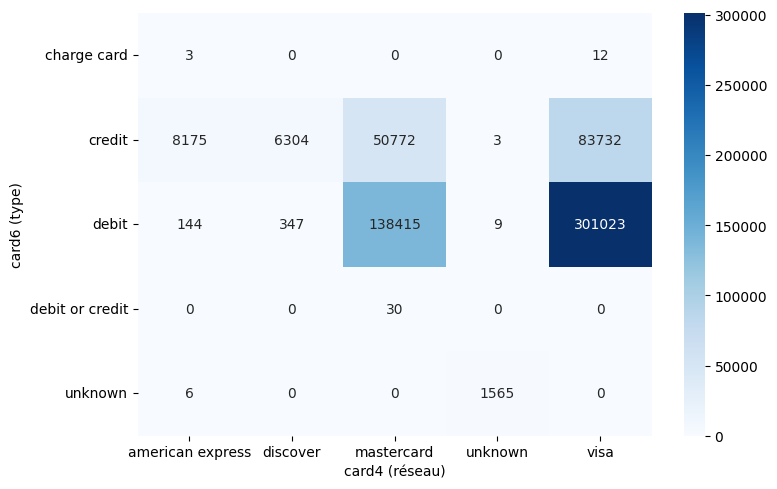

In [29]:

sample_df = df.select("card6", "card4").toPandas()

# Table croisée
cross_tab = pd.crosstab(sample_df["card6"], sample_df["card4"])

plt.figure(figsize=(8, 5))
sns.heatmap(cross_tab, annot=True, fmt="d", cmap="Blues")
plt.xlabel("card4 (réseau)")
plt.ylabel("card6 (type)")
plt.tight_layout()
plt.show()
cleanup(sample_df, cross_tab)

###  Interprétation – Fréquences conjointes `card4` × `card6`

- Les combinaisons **les plus fréquentes** sont :
  - `debit + visa` (= 301 023 lignes)
  - `debit + mastercard` (= 138 415)
  - `credit + visa` (= 83 732)
  - `credit + mastercard` (= 50 772)

- Certaines combinaisons sont **quasi absentes** : `charge card`, `unknown`, ou des croisements peu fréquents comme `credit + discover`.

 Conclusion :
- La majorité des transactions s'appuie sur des cartes **de débit Visa ou Mastercard**, ce qui représente un **comportement normal majoritaire**.
- Ces croisements peuvent être **encodés comme features combinées** (`card4_card6`) ou binarisés pour détecter des cas rares.


## 5.2 Analyse temporelle de la fraude

####  Objectif : Étudier l’évolution de la fraude dans le temps

Le champ `TransactionDT` est une **temps relatif exprimé en secondes** : il représente le **nombre de secondes depuis un point de référence** inconnu.  
Même s’il ne s’agit pas d’une date-calendrier, il permet d’**analyser des tendances temporelles** et de repérer des **pics de fraude**.

###  Préparation : transformation en jours

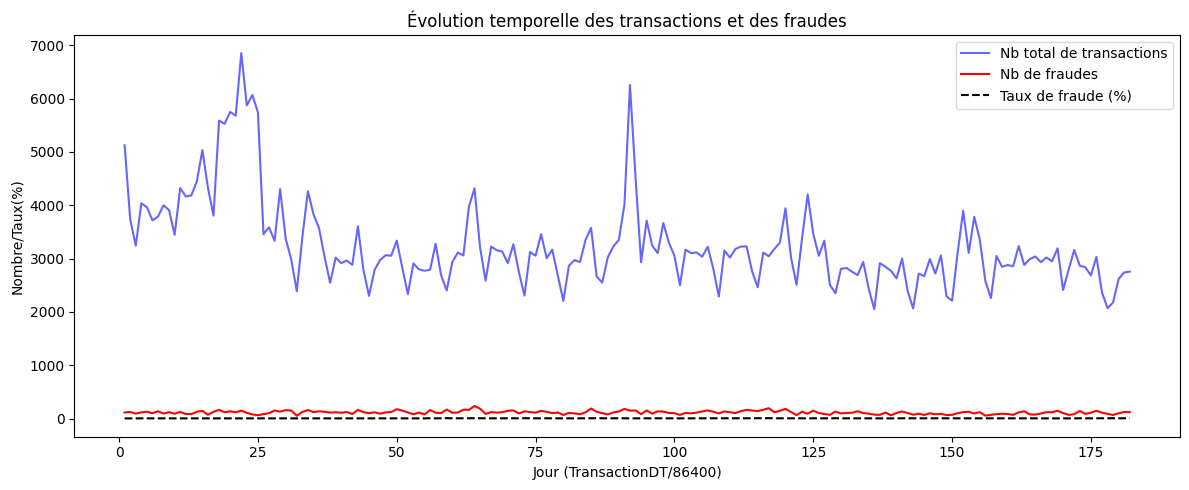

In [30]:
df = df.withColumn("TransactionDay", floor(col("TransactionDT") / 86400))

agg = (
    df.groupBy("TransactionDay")
      .agg(
          count("*").alias("nb_total"),
          count(when(col("isFraud") == 1, True)).alias("nb_fraudes"))
      .orderBy("TransactionDay"))

agg = agg.withColumn("taux_fraude", (col("nb_fraudes") / col("nb_total")) * 100)

agg_pd = agg.toPandas()

plt.figure(figsize=(12, 5))
plt.plot(agg_pd["TransactionDay"], agg_pd["nb_total"], label="Nb total de transactions", color="blue", alpha=0.6)
plt.plot(agg_pd["TransactionDay"], agg_pd["nb_fraudes"], label="Nb de fraudes", color="red")
plt.plot(agg_pd["TransactionDay"], agg_pd["taux_fraude"], label="Taux de fraude (%)", color="black", linestyle="--")

plt.xlabel("Jour (TransactionDT/86400)")
plt.ylabel("Nombre/Taux(%)")
plt.title("Évolution temporelle des transactions et des fraudes")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.show()

###  Interprétation – Évolution temporelle de la fraude

- Le volume de **transactions non frauduleuses** varie fortement sur les 200 premiers jours, avec plusieurs **pics d’activité**, notamment autour du jour 25 et 90.
- Les **fraudes restent relativement stables**, autour de **200 à 300 cas par jour**, avec **moins de volatilité**.
- Aucun **pic brutal** ou **saison de fraude identifiable**, mais quelques hausses modérées.

 Conclusion :
- `TransactionDT` converti en jours permet d’**exploiter des tendances globales**.
- Il est pertinent de créer une feature `day` ou `week`, voire un flag `is_weekend` ou `is_day_peak` pour le Feature Engineering.

## 5.3 Analyse des groupes spécifiques (`has_X`)

####  Objectif : Étudier l’impact de certaines variables binaires créées sur le taux de fraude

Durant la phase de nettoyage, plusieurs variables indicatrices (`has_X`) ont été ajoutées pour **préserver l'information de présence/absence** dans certaines colonnes très lacunaires, sans alourdir le dataset.

Nous allons explorer leur impact en trois étapes :

1. **`has_identity`** : distingue les transactions enrichies par des données d’identité
2. **Vue d’ensemble des `has_X`** : taux de présence + taux de fraude
3. **Zoom sur les plus pertinentes** (ex. : `has_D12`, `has_D14`, `has_id_03`, `has_D8`)


### Taux de fraude : `has_identity` 

In [31]:
fraude_par_identity = (
    df.groupBy("has_identity", "isFraud")
      .count()
      .groupBy("has_identity")
      .pivot("isFraud", [0, 1])
      .sum("count")
      .fillna(0)
)

fraude_par_identity = fraude_par_identity.withColumn(
    "taux_fraude_%", spark_round(col("1") / (col("0") + col("1")) * 100, 2)
).orderBy("has_identity")

fraude_par_identity.show()

+------------+------+-----+-------------+
|has_identity|     0|    1|taux_fraude_%|
+------------+------+-----+-------------+
|           0|436962| 9345|         2.09|
|           1|132915|11318|         7.85|
+------------+------+-----+-------------+



###  Interprétation – `has_identity` vs `isFraud`

Les résultats sont cohérents avec EDA brut :  
la variable `has_identity` conserve son **pouvoir discriminant élevé**, même après nettoyage.

Elle est confirmée comme feature robuste à conserver pour la modélisation.


### Aperçu global des `has_X`

####  Objectif : Identifier les indicateurs `has_X` dont la présence pourrait signaler un risque de fraude

Les colonnes concernées avaient un **taux de valeurs manquantes (80–90 %)**.  
Plutôt que de les supprimer, nous avons choisi de créer des **indicateurs binaires `has_X`**, qui indiquent simplement si la donnée est **présente (`1`) ou absente (`0`)**.


Cette section vise à :
-  Visualiser le **taux de présence** des indicateurs `has_X` dans le dataset
-  Calculer leur **taux de fraude** (quand `has_X = 1`)

L’objectif est d’identifier les variables partiellement renseignées qui, lorsqu’elles sont présentes, sont **associées à un risque de fraude plus élevé**, et méritent donc une analyse individuelle plus poussée.


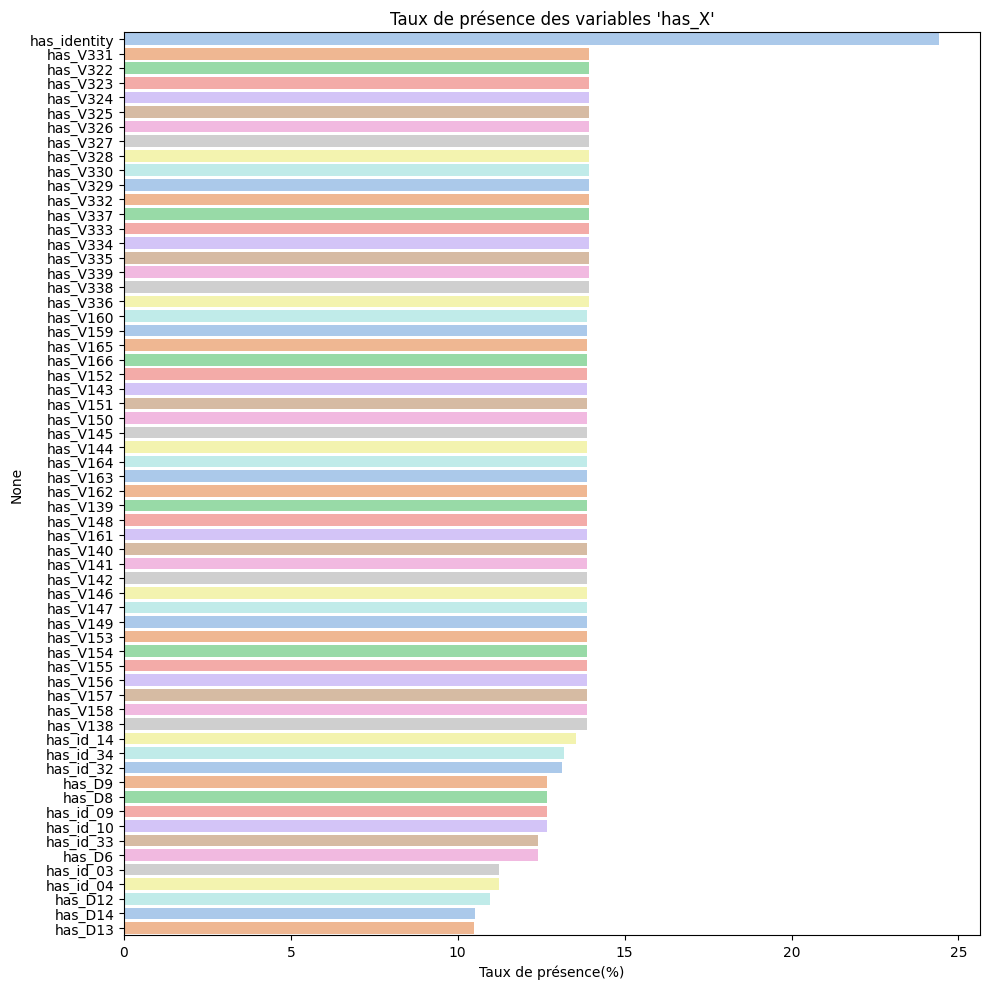

In [32]:
has_vars = [c for c in df.columns if c.startswith("has_")]

df_sample = df.select(has_vars + ["isFraud"]).toPandas()

# résumé des fréquences pour chaque has_X
presence_rates = df_sample[has_vars].mean().sort_values(ascending=False) * 100

plt.figure(figsize=(10, 10))
sns.barplot(x=presence_rates.values, y=presence_rates.index,hue=presence_rates.index, palette="pastel")
plt.xlabel("Taux de présence(%)")
plt.title("Taux de présence des variables 'has_X'")
plt.tight_layout()
plt.show()

cleanup(df_sample, presence_rates)

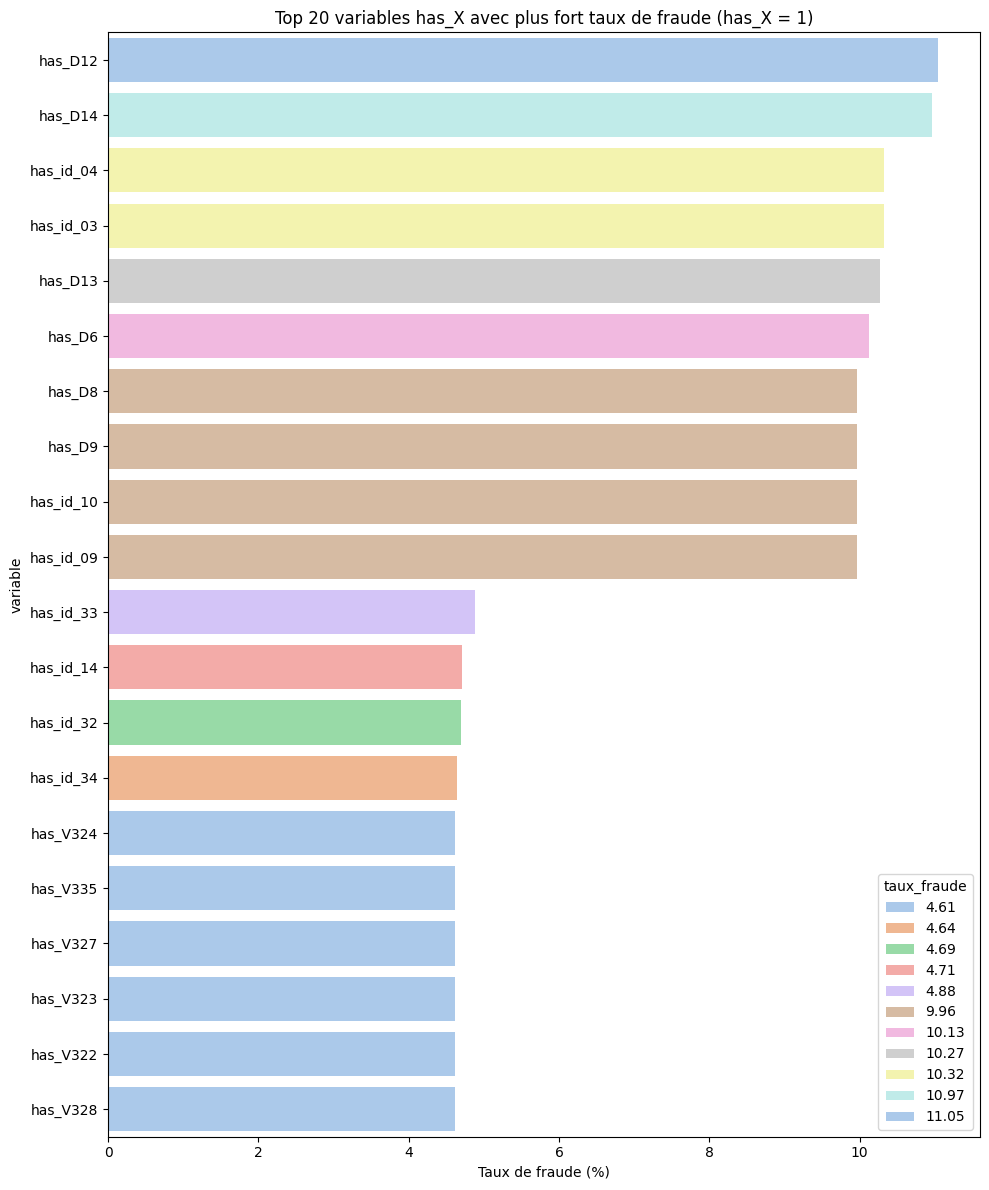

In [33]:
# liste des colonnes has_X (hors has_identity)
has_vars = [c for c in df.columns if c.startswith("has_") and c != "has_identity"]
df_sample = df.select(has_vars + ["isFraud"]).sample(fraction=0.1).toPandas()

# Calcul des taux de fraude pour has_X = 1
resultats = []
for colname in has_vars:
    subset = df_sample[df_sample[colname] == 1]
    if len(subset) > 0:
        taux = subset["isFraud"].mean() * 100
        resultats.append((colname, len(subset), __builtins__.round(taux, 2)))

df_fraude_hasX = pd.DataFrame(resultats, columns=["variable", "n_obs", "taux_fraude"])
df_fraude_hasX = df_fraude_hasX.sort_values("taux_fraude", ascending=False)


plt.figure(figsize=(10, 12))
sns.barplot(data=df_fraude_hasX.head(20), x="taux_fraude", y="variable",hue="taux_fraude", palette="pastel")
plt.title("Top 20 variables has_X avec plus fort taux de fraude (has_X = 1)")
plt.xlabel("Taux de fraude (%)")
plt.tight_layout()
plt.show()
cleanup(df_sample, df_fraude_hasX)

####  Interprétation – Analyse globale des variables `has_X`

L’analyse des variables indicatrices `has_X` montre deux enseignements importants :

-  **Présence dans le dataset** : La plupart des `has_X` sont présentes dans **10 à 25 %** des lignes. Elles permettent donc de **capturer la structure manquante de colonnes partiellement remplies**, sans déséquilibrer le jeu de données.
  - `has_identity` est la plus fréquente (~25 %)
  - Certaines comme `has_D12`, `has_D13`, `has_D14` ou `has_id_03` ont une **faible fréquence (< 15 %)**, ce qui reflète des données rares mais potentiellement très utiles.

-  **Taux de fraude conditionnel (has_X = 1)** : C’est ici que les choses deviennent intéressantes. Plusieurs variables peu fréquentes affichent un **taux de fraude très élevé** :
  - `has_D12` dépasse **11 % de fraude**
  - `has_D13`, `has_D14`, `has_id_04`, `has_D8`, `has_D6` sont toutes **au-dessus de 9 %**
  - À l’inverse, certaines variables très fréquentes comme `has_V138`, `has_V139`, `has_V331` ont des taux proches de la moyenne globale (~3.5 %) → donc peu discriminantes.

Cela confirme un effet classique : **les données les plus rares peuvent contenir les signaux les plus forts**, surtout en détection de fraude.


 En synthèse :
- Nous allons maintenant **approfondir les variables les plus discriminantes**, à savoir :
  - `has_D12`, `has_D14`, `has_id_03`, `has_D8`



### Analyse du lien entre `has_D12` & `has_D14` et la fraude

In [34]:
# stats globales
stats_d12 = (
    df.groupBy("has_D12", "isFraud")
    .count()
    .groupBy("has_D12")
    .pivot("isFraud", [0, 1])
    .sum("count")
    .fillna(0)
    .withColumn("total", col("0") + col("1"))
    .withColumn("taux_fraude", spark_round(col("1") / col("total") * 100, 2))
    .orderBy("has_D12"))

stats_d12.show()


+-------+------+-----+------+-----------+
|has_D12|     0|    1| total|taux_fraude|
+-------+------+-----+------+-----------+
|      0|512758|13065|525823|       2.48|
|      1| 57119| 7598| 64717|      11.74|
+-------+------+-----+------+-----------+



In [35]:
### analyse détaillé de la variable 'has_D14'

stats_d14 = ( df.groupBy("has_D14", "isFraud")
    .count()
    .groupBy("has_D14")
    .pivot("isFraud", [0, 1])
    .sum("count")
    .fillna(0)
    .withColumn("total", col("0") + col("1"))
    .withColumn("taux_fraude", spark_round(col("1") / col("total") * 100, 2))
    .orderBy("has_D14"))

stats_d14.show()

+-------+------+-----+------+-----------+
|has_D14|     0|    1| total|taux_fraude|
+-------+------+-----+------+-----------+
|      0|514903|13450|528353|       2.55|
|      1| 54974| 7213| 62187|       11.6|
+-------+------+-----+------+-----------+



###  Interprétation – Variables `has_D12` et `has_D14`

L’analyse des indicateurs `has_D12` et `has_D14` met en évidence des tendances nettes :

- Lorsqu’une **valeur est présente** (`has_D12 = 1` ou `has_D14 = 1`), le **taux de fraude dépasse les 11 %** :
- `has_D12 = 1` : **11,74 %**, contre **2,48 %** lorsque la valeur est absente ;
- `has_D14 = 1` : **11,60 %**, contre **2,55 %** lorsque la valeur est absente.

Cela confirme que la **présence de certaines variables comportementales**, même sans en connaître la valeur exacte, est **hautement informative** pour détecter la fraude.

 Conclusion :
- Ces deux variables `has_D12` et `has_D14` seront **conservées pour la modélisation**.
- Cette approche **permet d'exploiter l'information issue du "manquant"**, en capturant des signaux faibles souvent négligés.

## 5.4 Analyse des corrélations numériques

####  Objectif : Identifier les variables numériques redondantes ou fortement corrélées

L’objectif de cette section est de :
- Détecter les **corrélations linéaires fortes** entre variables numériques
- **Éviter les redondances** dans les futures étapes de modélisation
- Faciliter une éventuelle **réduction de dimension (ex. : ACP)**


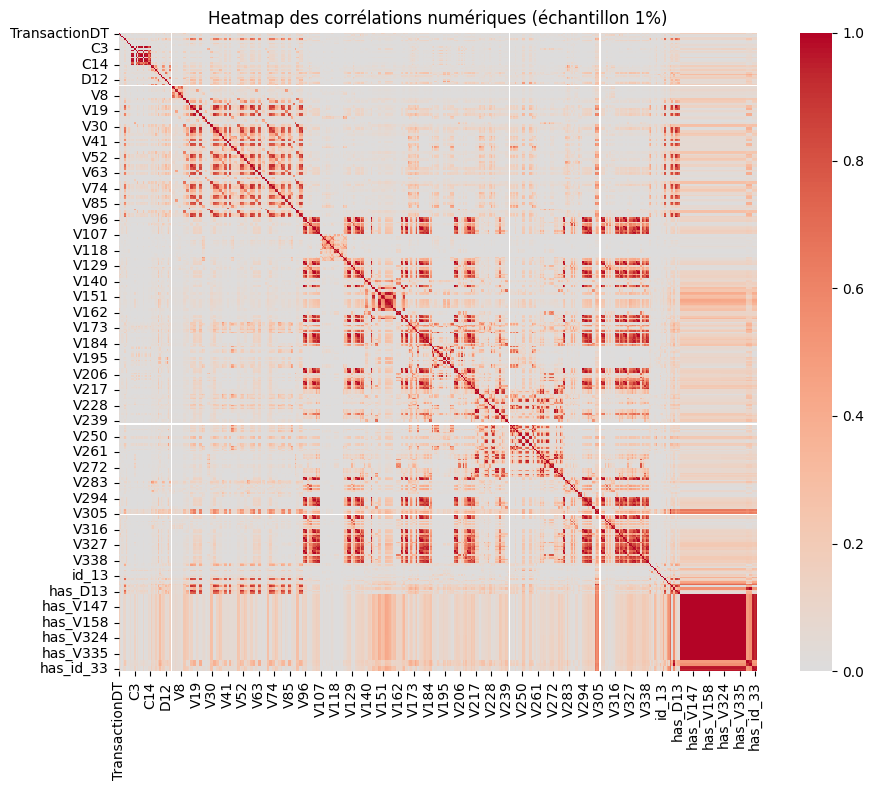

In [36]:
numeric_cols = [c for c, t in df.dtypes if t in ("double", "int") and c != "isFraud"]

df_sample = df.select(numeric_cols).sample(fraction=0.01).toPandas()

# Calcul du corrélation
corr_matrix = df_sample.corr().abs()

# heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0, square=True)
plt.title("Heatmap des corrélations numériques (échantillon 1%)")
plt.tight_layout()
plt.show()
cleanup(df_sample, corr_matrix)

###  Interprétation – Corrélations numériques

L’analyse des corrélations entre variables numériques (échantillon 1 %) révèle plusieurs éléments clés :

-  **Majoritairement peu de corrélation** entre les variables, ce qui confirme une **diversité d’information utile** pour les modèles.
-  Quelques **blocs fortement corrélés** apparaissent clairement :
  - Notamment au sein des familles de variables `V1xx`, `V3xx`, ou `id_xx`
  - Ces redondances structurelles devront être **prises en compte lors du feature selection ou via une réduction de dimension**
- Certains indicateurs `has_X` sont également corrélés entre eux, ce qui peut signaler :
  - Une dépendance naturelle (ex. : `has_id_03` et `has_id_04`)
  - Ou une origine commune (colonnes dérivées d’un même champ source)

 Implications pour la suite :
- Aucune variable **n’est à supprimer immédiatement** sur base de redondance excessive.
- Un **travail complémentaire de regroupement ou transformation** ( ACP, regroupement de blocs `Vxxx`) pourra être envisagé dans la phase de feature engineering.

Cette cartographie des corrélations **conclut l’EDA approfondie** et servira de base stratégique pour la création de nouvelles features optimisées.